<a href="https://colab.research.google.com/github/contatolbonfim-ship-it/aula_git_ad/blob/main/estatistica/01_estatistica_descritiva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![title](https://ik.imagekit.io/vzr6ryejm/colab/jupyter_notebook-ad.drawio.png)

## 🔧 Preparação
Esta primeira célula carrega as ferramentas e os dados. Você só precisa executá-la.

### 📚 Importando as Bibliotecas

In [2]:
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

from google.colab import drive     # montar o Google Drive para salvar os arquivos do notebook
from google.colab import files     # upload de arquivos do computador para o Google Drive

import numpy as np                 # contas matemáticas (ex.: raiz quadrada)
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (10, 6)   # tamanho padrão dos gráficos



### 🔄 Carregando a base de dados

In [4]:
drive.mount("/content/drive")      # vai pedir autorização na primeira vez
pasta_colab = Path("/content/drive/MyDrive/Colab Notebooks") # Caminho da pasta do Google Colab no drive
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/estatistica/dados") # Caminho da pasta com os dados no drive
caminho_do_csv = pasta_dados / "alunos.csv"

# Se o arquivo ainda não existir no Drive, pede o upload e grava na pasta indicada
if not caminho_do_csv.exists():
    pasta_dados.mkdir(parents=True, exist_ok=True)   # cria a pasta "dados" se faltar
    print("Base não encontrada. Selecione o arquivo CSV para enviar:")
    enviados = files.upload()                        # abre o seletor de arquivos
    nome_enviado = next(iter(enviados))              # nome do arquivo escolhido
    shutil.move(nome_enviado, caminho_do_csv)        # grava como base_ficticia_faker.csv
    print(f"Arquivo salvo em: {caminho_do_csv}")

dados = pd.read_csv(caminho_do_csv)
dados.head(10)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,id_aluno,curso,turno,mes_da_matricula,horas_estudo_semana,horas_sono_noite,numero_de_faltas,nota_final,renda_familiar_mensal,tempo_de_deslocamento_min,nota_diagnostico,aproveitamento_atividades_pct,nivel_engajamento
0,ALU-2664-EN,Saúde,Tarde,Jan,14.5,6.9,2,8.3,26709.31,45,7.5,70.5,Alto
1,ALU-1107-KJ,Direito,Tarde,Jan,15.4,8.2,2,8.5,5607.19,86,8.9,84.5,Alto
2,ALU-8645-CG,Engenharia,Noite,Abr,9.3,7.2,7,3.8,3604.23,24,3.2,57.6,Médio
3,ALU-0836-KV,Engenharia,Noite,Ago,6.1,7.1,4,4.3,2684.80,44,2.9,22.7,Baixo
4,ALU-7042-PH,Saúde,Tarde,Jan,20.2,6.4,1,8.8,2993.52,48,4.8,66.5,Alto
5,ALU-0495-PP,Saúde,Tarde,Fev,11.8,8.0,3,6.7,3174.36,79,7.9,76.4,Médio
6,ALU-2226-MT,Direito,Noite,Jan,6.2,6.3,8,4.1,4005.45,22,7.6,82.1,Baixo
7,ALU-9584-SS,Direito,Noite,Jan,12.1,8.3,2,6.5,6212.80,60,7.1,82.1,Médio
8,ALU-0060-PR,Direito,Noite,Dez,9.3,5.9,5,3.9,5165.29,71,7.9,78.6,Médio
9,ALU-6496-HT,Saúde,Manhã,Ago,10.7,7.8,3,5.5,4318.47,19,9.6,88.8,Médio


In [11]:
dados.dtypes

,0
id_aluno,object
curso,object
turno,object
mes_da_matricula,object
horas_estudo_semana,float64
horas_sono_noite,float64
numero_de_faltas,int64
nota_final,float64
renda_familiar_mensal,float64
tempo_de_deslocamento_min,int64


## 1️⃣ Conhecendo a nossa base de dados

In [8]:
# Digite seu código aqui para análise dos dados
linhas, colunas = dados.shape
print(f"A base de dados tem {linhas} linhas e {colunas} colunas.")

A base de dados tem 50 linhas e 13 colunas.


## 2️⃣ Média
É a **soma** de todos os valores dividida pela **quantidade** de valores:

$$\bar{x} = \frac{\sum x_i}{n}$$

Mostra o **desempenho geral** do grupo. Para enxergar a conta, vamos usar **só 5 alunos** primeiro.

### Média Manual selecionando 5 alunos

In [17]:
cinco_notas = dados["nota_final"].head()
print(cinco_notas.tolist())

soma = cinco_notas.sum()
quantidade = len(cinco_notas)
media = soma/quantidade

print(f"Média: {media}")

print(f"Média: {cinco_notas.mean()}")

[8.3, 8.5, 3.8, 4.3, 8.8]
Média: 6.74
Média: 6.74



### Média - Notas de todos os alunos

In [18]:
print(f"Média da Turma: {dados["nota_final"].mean():.2f}")

Média da Turma: 6.09


## 3️⃣ Mediana
É o **valor do meio** quando os dados estão **em ordem**. Metade dos valores fica abaixo dela e metade acima.
- Quantidade **ímpar** → o valor central.
- Quantidade **par** → a média dos dois valores centrais.

### Mediana manual - Quantidade Ímpar

In [30]:
notas_ordenadas = cinco_notas.sort_values().to_list
print(notas_ordenadas)

print(f"Mediana: {cinco_notas.median()}")

<bound method IndexOpsMixin.tolist of 2    3.8
3    4.3
0    8.3
1    8.5
4    8.8
Name: nota_final, dtype: float64>
Mediana: 8.3


### Mediana manual - Quantidade Par

In [32]:
seis_notas = dados["nota_final"].head(6)
seis_notas_ordenadas = seis_notas.sort_values().to_list()
print(seis_notas_ordenadas)

notas_centrais = seis_notas_ordenadas[2:4]
mediana = sum(notas_centrais) / len(notas_centrais)
print(f"Mediana Manual: {mediana}")

print(f"Mediana: {seis_notas.median()}")



[3.8, 4.3, 6.7, 8.3, 8.5, 8.8]
Mediana Manual: 7.5
Mediana: 7.5


### Mediana - Notas de todos os alunos

In [33]:
print(f"Mediana de todas as notas: {dados['nota_final'].median()}")

Mediana de todas as notas: 6.25


### Gráfico Histograma - Média e Mediana de todos os alunos

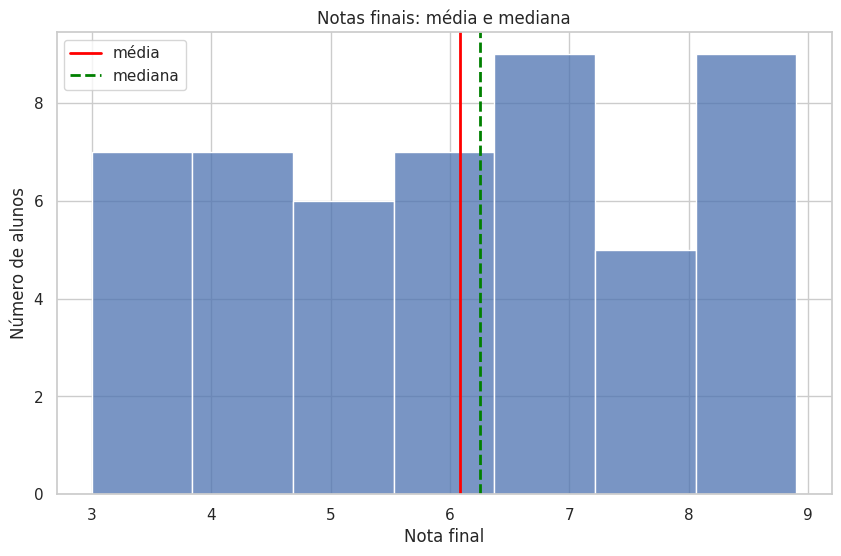

In [34]:
sns.histplot(data=dados, x="nota_final", bins=7)
plt.axvline(dados["nota_final"].mean(), color="red", linewidth=2, label="média")
plt.axvline(dados["nota_final"].median(), color="green", linestyle="--", linewidth=2, label="mediana")
plt.title("Notas finais: média e mediana")
plt.xlabel("Nota final")
plt.ylabel("Número de alunos")
plt.legend()
plt.show()

### O quanto a distribuição dos dados é simétrica em relação ao seu centro?

* **Skew ≈ 0:** distribuição simétrica. Os dados se espalham de forma parecida dos dois lados da média, e média e mediana ficam próximas.
* **Skew negativo:** assimetria à esquerda. A cauda do gráfico se estica para os valores baixos, e a média fica abaixo da mediana.
* **Skew positivo:** assimetria à direita. A cauda se estica para os valores altos, e a média fica acima da mediana.

**Regra prática:** valores entre -0,5 e 0,5 indicam distribuição aproximadamente simétrica. Entre 0,5 e 1 (em módulo), assimetria moderada. Acima de 1, forte.

In [36]:
dados["nota_final"].skew()

np.float64(-0.03749106115678723)

**Digite aqui as conclusões**

## 4️⃣ Moda
É o valor que **mais se repete**. Funciona muito bem para **categorias** e **contagens**.

In [43]:
print(f"Turno com mais alunos: {dados["turno"].mode()[0]}")

print("\nQuantidade de alunos por turno:")
print(dados["turno"].value_counts())

print(f"Notas mais comuns: {dados["nota_final"].mode().tolist()}")

print(f"Turno com mais alunos: {dados['turno'].mode()[0]}")

# print("\nQuantidade de alunos por turno:")
# print(dados["turno"].value_counts())

print(f"Faltas mais frequentes: {dados['numero_de_faltas'].mode()[0]}")

print(f"Notas mais comuns: {dados['nota_final'].mode().tolist()}")

Turno com mais alunos: Tarde

Quantidade de alunos por turno:
turno
Tarde    19
Noite    18
Manhã    13
Name: count, dtype: int64
Notas mais comuns: [3.8, 4.3, 5.3, 5.8, 6.3, 6.7, 8.0, 8.8]
Turno com mais alunos: Tarde
Faltas mais frequentes: 3
Notas mais comuns: [3.8, 4.3, 5.3, 5.8, 6.3, 6.7, 8.0, 8.8]


### Gráfico de Colunas - Quantos alunos tem cada número de faltas?

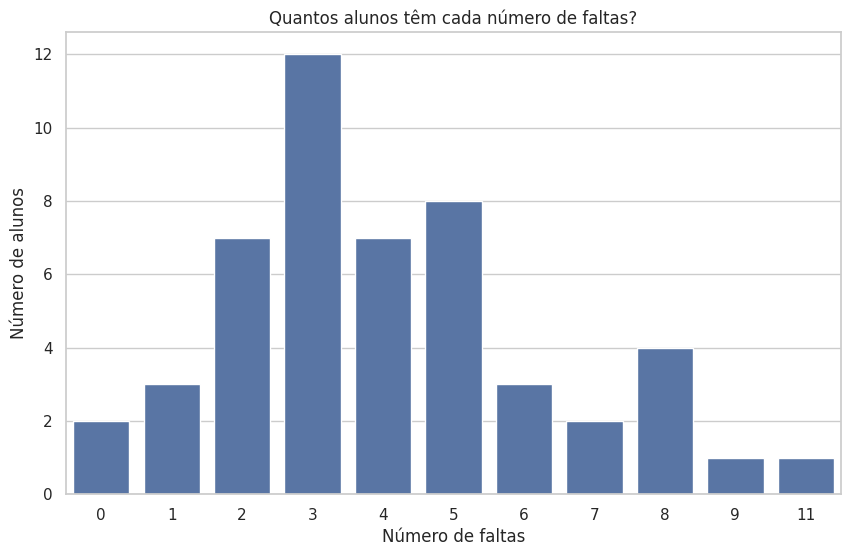

In [44]:
# Gráfico de colunas: a moda é a coluna mais alta
sns.countplot(data=dados, x="numero_de_faltas")     # countplot conta quantas vezes cada valor aparece
plt.title("Quantos alunos têm cada número de faltas?")
plt.xlabel("Número de faltas")
plt.ylabel("Número de alunos")
plt.show()


## 5️⃣ Amplitude
Mostra **quão espalhados** estão os dados: a diferença entre o **maior** e o **menor** valor.

$$A = x_{máx} - x_{mín}$$



In [45]:
maior_nota = dados["nota_final"].max()
menor_nota = dados["nota_final"].min()

print(f" Amplitude: {maior_nota - menor_nota}")





 Amplitude: 5.9


A amplitude das notas foi de 5,9 pontos (8,9 − 3,0), o que indica, mas não conclui que existe uma dispersão considerável: há uma distância grande entre o aluno com pior desempenho e o aluno com melhor desempenho da turma.
 **Digite aqui as conclusões**

## 6️⃣ Variância
A **variância** mede **o quanto os valores se afastam da média**. Ela é o passo que vem **antes** do desvio padrão.

**Passo a passo:**
1. Calcule a **média**.
2. **Subtraia a média** de cada valor.
3. **Eleve cada diferença ao quadrado** (assim, diferenças positivas e negativas não se cancelam).
4. **Some** todos os quadrados.
5. **Divida** pela quantidade de dados.

$$s^2 = \frac{\sum (x_i - \bar{x})^2}{N}$$

> ⚠️ Use **$N$** quando os dados são a **população inteira** e **$n-1$** quando são uma **amostra** (o caso mais comum). O Pandas usa **$n-1$** por padrão.

> 💡 Como as diferenças são elevadas ao quadrado, a variância fica em **unidades ao quadrado** (notas viram "pontos²"), o que é difícil de interpretar. É por isso que existe o desvio padrão (próxima seção).

De novo, começamos pequeno, com os 5 alunos:

### Cálculo manual da Variância

In [46]:
media = cinco_notas.mean()                                           # passo 1: média

tabela_da_conta = pd.DataFrame({"nota": cinco_notas})
tabela_da_conta["nota - média"] = cinco_notas - media                # passo 2: diferença para a média
tabela_da_conta["(nota - média)²"] = (cinco_notas - media) ** 2      # passo 3: elevar ao quadrado
display(tabela_da_conta.round(2))

soma_dos_quadrados = tabela_da_conta["(nota - média)²"].sum()        # passo 4: somar
print(f"Soma dos quadrados = {soma_dos_quadrados:.2f}")

variancia_populacional = soma_dos_quadrados / 5                      # passo 5 (÷ N)
variancia_amostral = soma_dos_quadrados / (5 - 1)                    # passo 5 (÷ n−1)
print(f"Variância Populacional (÷ N) = {variancia_populacional:.2f} pontos²")
print(f"Variância Amostral (÷ n-1) = {variancia_amostral:.2f} pontos²")

,nota,nota - média,(nota - média)²
0,8.3,1.56,2.43
1,8.5,1.76,3.10
2,3.8,-2.94,8.64
3,4.3,-2.44,5.95
4,8.8,2.06,4.24


Soma dos quadrados = 24.37
Variância Populacional (÷ N) = 4.87 pontos²
Variância Amostral (÷ n-1) = 6.09 pontos²


### Cálculo da Variância via função

In [47]:
print(f"Variância Populacional (÷ N) = {dados['nota_final'].var(ddof=0):.2f} pontos²")
print(f"Variância Amostral (÷ n-1) = {dados['nota_final'].var():.2f} pontos²")

Variância Populacional (÷ N) = 3.10 pontos²
Variância Amostral (÷ n-1) = 3.16 pontos²


A variância das notas dos 50 alunos foi de 3,16 pontos², o que equivale a um desvio padrão de cerca de 1,78 ponto. Ou seja, em média, as notas se afastam da média da turma em torno de 1,8 ponto, para mais ou para menos. Considerando a amplitude de 5,9 pontos, trata-se de uma dispersão moderada, com a maior parte dos alunos concentrada perto da média.

### Variância - Notas de todos os alunos

In [ ]:
# Digite seu código aqui para análise dos dados

**Digite aqui as conclusões**

## 7️⃣ Desvio padrão
O **desvio padrão** é a **raiz quadrada da variância**. Com isso, o valor **volta à unidade original** (pontos) e fica fácil de interpretar: mostra **o quanto os valores se afastam da média**, em média. Quanto **maior**, mais **espalhados** estão os dados.

$$s = \sqrt{s^2}$$

### Cálculo manual do Desvio Padrão

In [ ]:
# Digite seu código aqui para análise dos dados

### Cálculo manual do Desvio Padrão - Notas de todos os alunos

In [48]:
print(f"Desvio Padrão: {dados["nota_final"].std()}")

Desvio Padrão: 1.7775975532230264


In [51]:
dados["nota_final"].describe()

,nota_final
count,50.000000
mean,6.088000
std,1.777598
min,3.000000
25%,4.375000
50%,6.250000
75%,7.650000
max,8.900000


## 8️⃣ Outliers: quando a média engana
**Outliers** são valores **muito diferentes** do restante. Eles **puxam a média**, mas quase não mexem na **mediana**. Por isso, em dados como **renda**, a mediana representa melhor o "valor típico".

### Cálculo da Média e Mediana da Renda Mensal Familiar

In [ ]:
# Digite seu código aqui para análise dos dados

### Gráfico - Média e Mediana da Renda Mensal Familiar

In [ ]:
# Digite seu código aqui para análise dos dados

**Digite aqui as conclusões**

### O quanto a distribuição dos dados é simétrica em relação ao seu centro?

* **Skew ≈ 0:** distribuição simétrica. Os dados se espalham de forma parecida dos dois lados da média, e média e mediana ficam próximas.
* **Skew negativo:** assimetria à esquerda. A cauda do gráfico se estica para os valores baixos, e a média fica abaixo da mediana.
* **Skew positivo:** assimetria à direita. A cauda se estica para os valores altos, e a média fica acima da mediana.

**Regra prática:** valores entre -0,5 e 0,5 indicam distribuição aproximadamente simétrica. Entre 0,5 e 1 (em módulo), assimetria moderada. Acima de 1, forte.

In [ ]:
# Digite seu código aqui para análise dos dados

**Digite aqui as conclusões**

## 9️⃣ Quartis, percentis e IQR
São medidas de **posição**: dividem os dados **em ordem** em partes iguais.

| Medida | Divide em | Significado |
|---|---|---|
| **Quartis** (Q1, Q2, Q3) | 4 partes | Q1 = 25% dos valores ficam abaixo · Q2 = **mediana** (50%) · Q3 = 75% |
| **Percentis** (P1 a P99) | 100 partes | P90 = 90% dos valores ficam abaixo dele |
| **IQR** | | $IQR = Q_3 - Q_1$: a "largura" dos 50% do meio |

💡 O quartil é só um **tipo de percentil** (Q1 = P25, Q2 = P50, Q3 = P75). Por isso o Pandas usa **a mesma função** para os dois: `.quantile()`, passando um número de 0 a 1.

### Quartis

In [ ]:
# Digite seu código aqui para análise dos dados

### Percentis

In [ ]:
# Digite seu código aqui para análise dos dados

### Gráfico Box Plot - Representação dos Quartis

In [ ]:
# Digite seu código aqui para análise dos dados

**Digite aqui as conclusões**

## 🔟 Prática: comparando dois turnos
Você é da coordenação e quer **comparar o turno da Manhã com o da Noite**. Calcule média, mediana, moda, amplitude, variância e desvio padrão da **nota final** de cada um.

**Perguntas:**
1. O que média e mediana dizem sobre cada turno?
2. O que o desvio padrão diz sobre a variação das notas em cada turno?
3. Como a coordenação poderia usar isso?

In [ ]:
# Digite seu código aqui para análise dos dados

### Gráfico - Nota Média - Manhã e Noite

In [ ]:
# Digite seu código aqui para análise dos dados

**Digite aqui as conclusões**